# Global EDA Tools - analysis notebook

Runs **inside Crucible**: `igny run jupyter lab` (interactive) or
`igny run jupyter nbconvert --to notebook --execute notebooks/analysis.ipynb` (headless).

It calls the same `scripts/run_analysis.py` as the pipeline, so the plots here are byte-for-byte the
plots in `outputs/` and in the report. Libraries: Python standard library + numpy + matplotlib
(pandas is not in the Crucible catalog).

In [1]:
import sys, csv, json
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "scripts").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "scripts"))
import common
common.drop_user_site()
import numpy as np, matplotlib
print("python", sys.version.split()[0], "| numpy", np.__version__, "| matplotlib", matplotlib.__version__)
print("numpy from:", Path(np.__file__).parent)

python 3.12.10 | numpy 2.5.4 | matplotlib 3.11.2
numpy from: C:\Users\prava\Crucible\tools\numpy\2.5.4\numpy


In [2]:
import run_analysis
run_analysis.main()            # rebuilds outputs/*.png, *.csv, summary.json, findings.md from the clean CSV
print((ROOT / "outputs" / "findings.md").read_text(encoding="utf-8"))

analysis complete: 131 tools; plots and tables in C:\Users\prava\Downloads\global-eda-tools-explorer (2)\global-eda-tools-explorer\outputs
# Findings (auto-generated from the dataset, snapshot 2026-10-15)

Generated by `scripts/run_analysis.py`; every number below is computed from `data/processed/eda_tools_clean.csv`. It describes the collected catalog, not every EDA tool in the world.

- Tools in the dataset: **131** (from 268 source records; 89 tools combine several sources)
- Licence model: commercial **67**, open-source **44**, freeware **7**, unknown **13**
- Largest primary category: **simulation (39)**; categories covered: 10 of 10
- Regions with documented vendor origin: North America 49, Europe 5, Asia 4, Oceania 2
- Most represented country: **United States (49)**
- Tools with a release in the last 3 years (2024-2026): 36 of 58 with a documented release
- Earliest documented first release: 1973
- Least complete fields: repository_url 23% filled, first_release_year 23% filled,

## 1. Tools per design-flow category

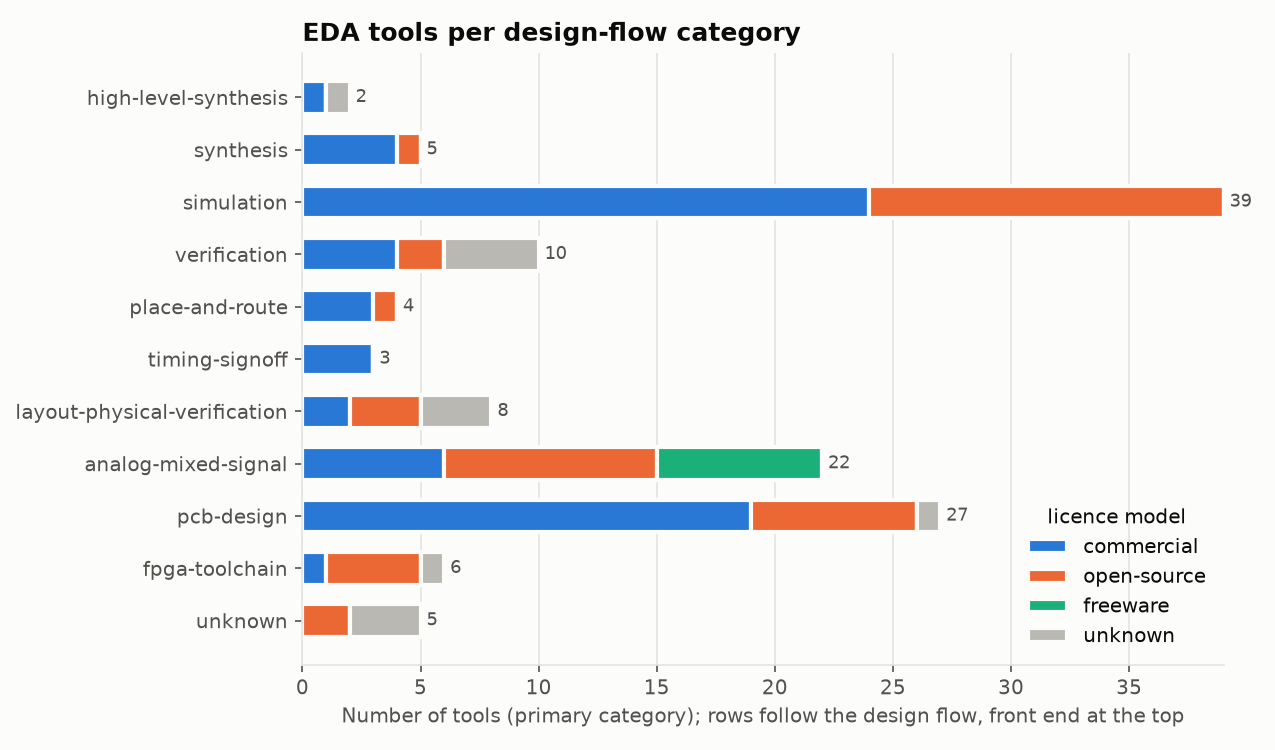

In [3]:
from IPython.display import Image, display
display(Image(filename=str(ROOT / "outputs" / "tools_by_category.png")))

## 2. Commercial vs open-source vs freeware

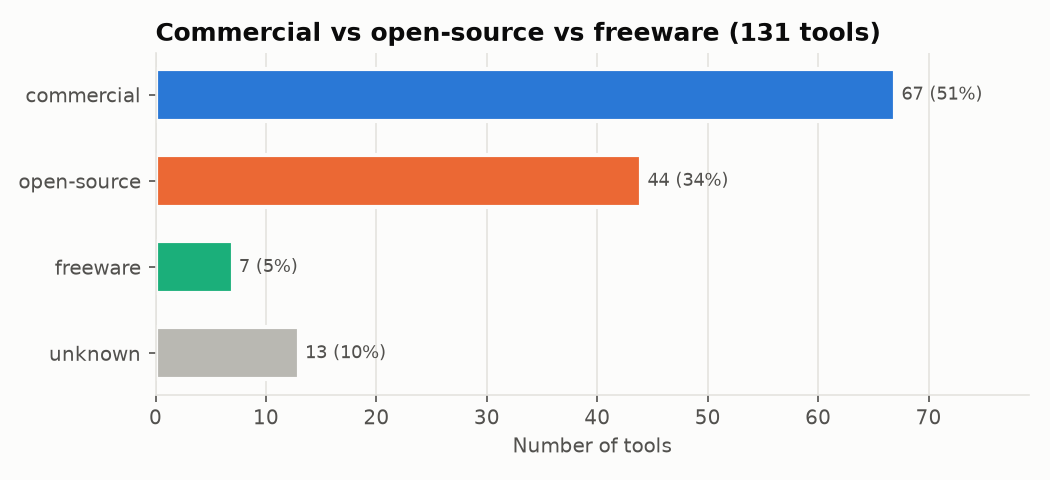

In [4]:
display(Image(filename=str(ROOT / "outputs" / "license_distribution.png")))

## 3. Tools per region and country of vendor origin

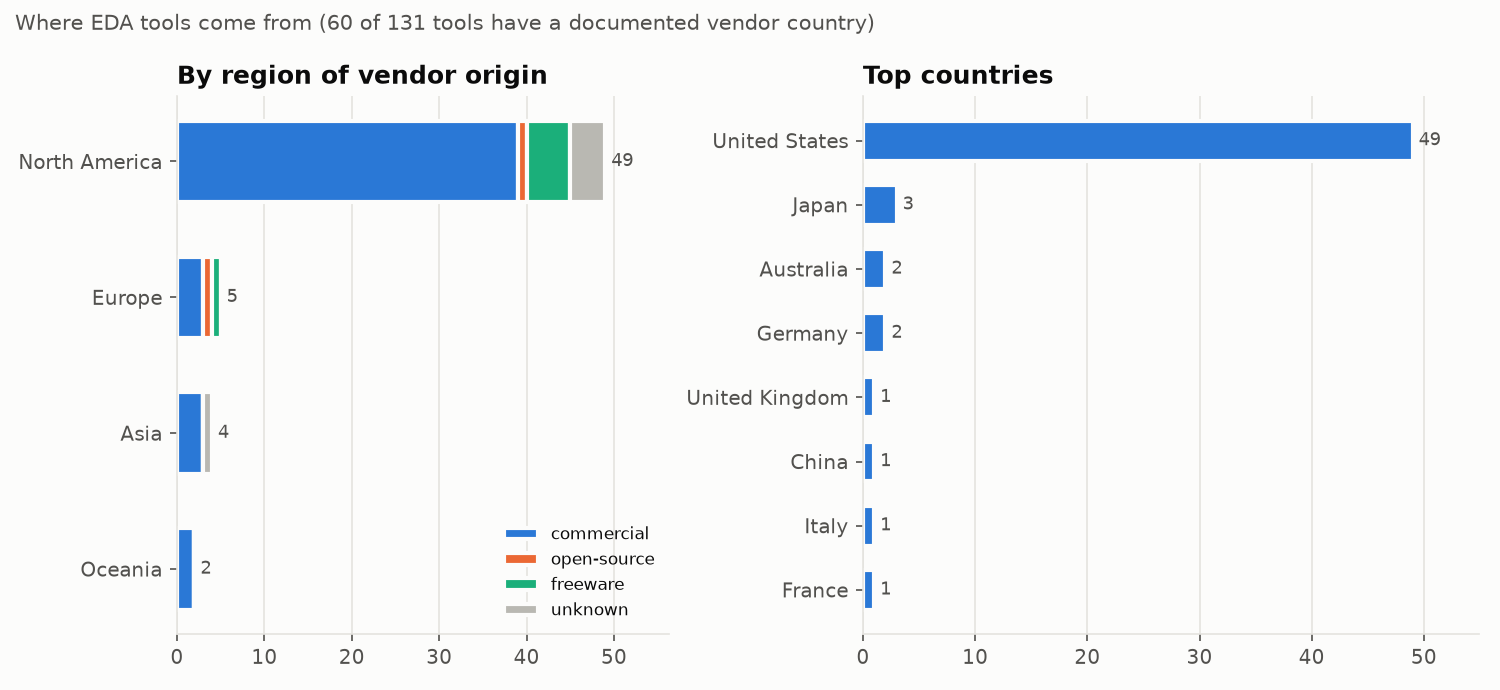

In [5]:
display(Image(filename=str(ROOT / "outputs" / "tools_by_region.png")))

## 4. Release activity over time

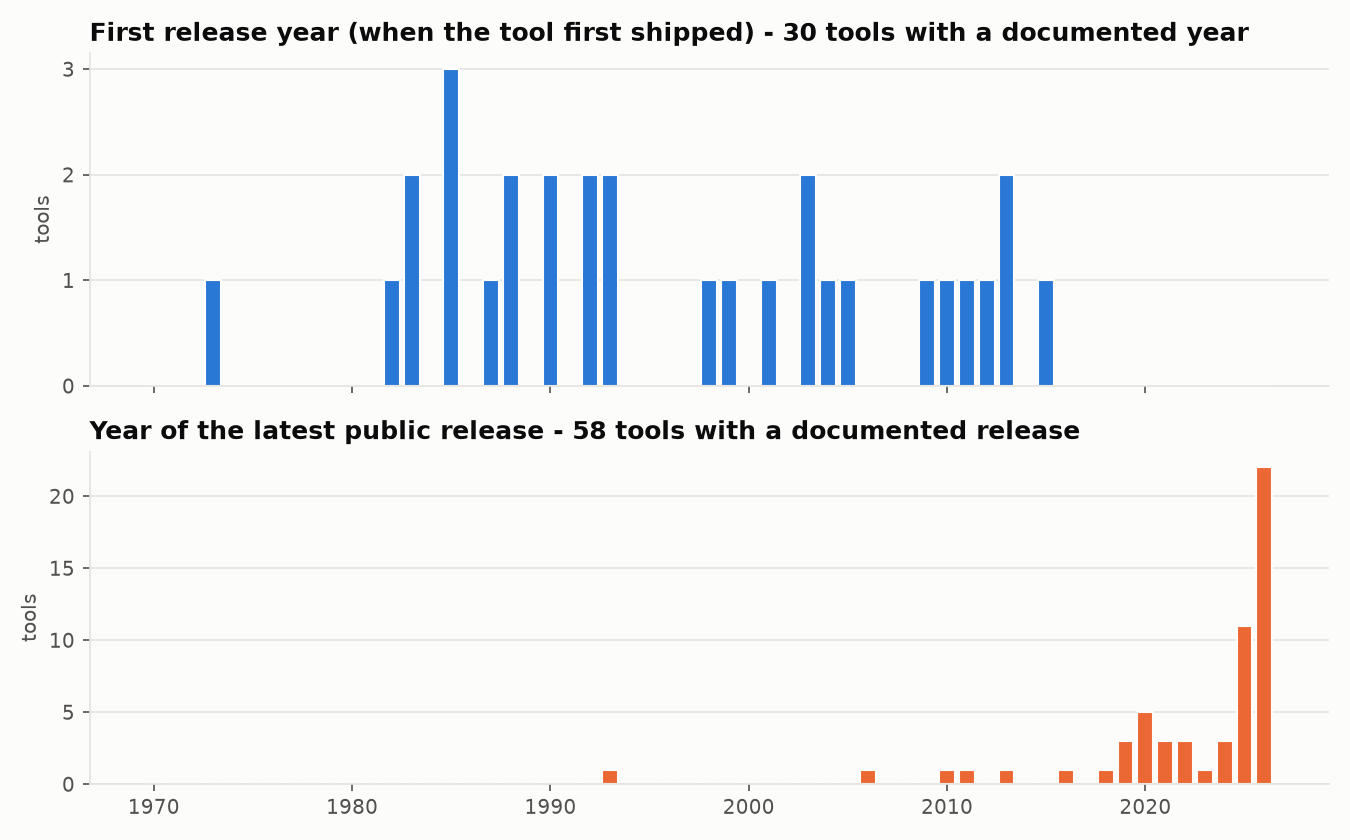

In [6]:
display(Image(filename=str(ROOT / "outputs" / "release_activity.png")))

## 5. Platforms, completeness, formats, vendors

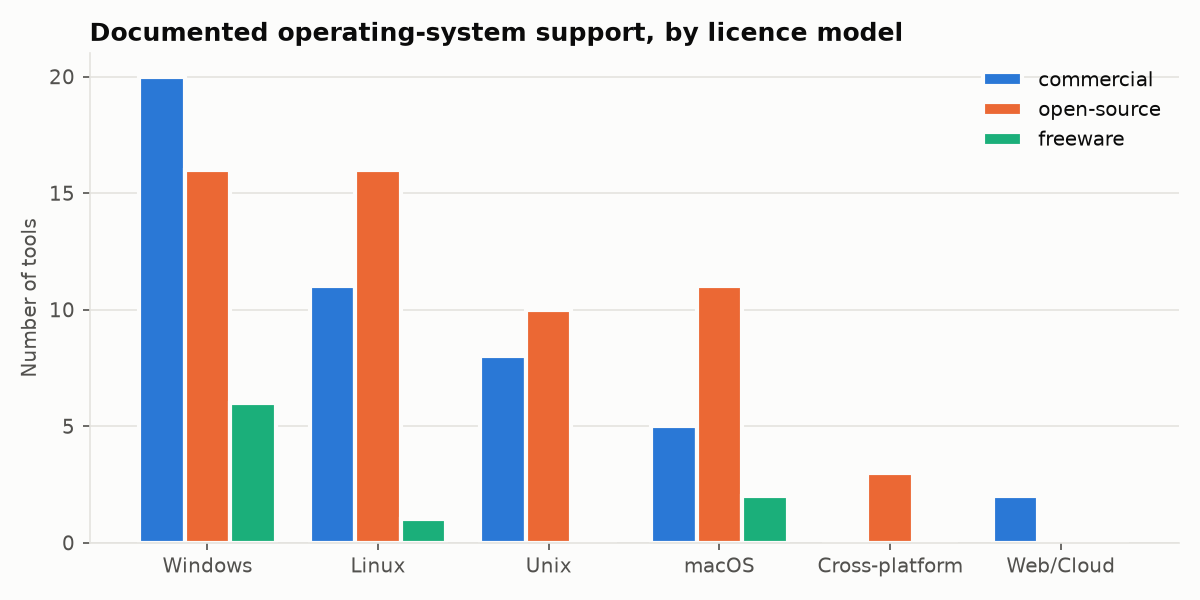

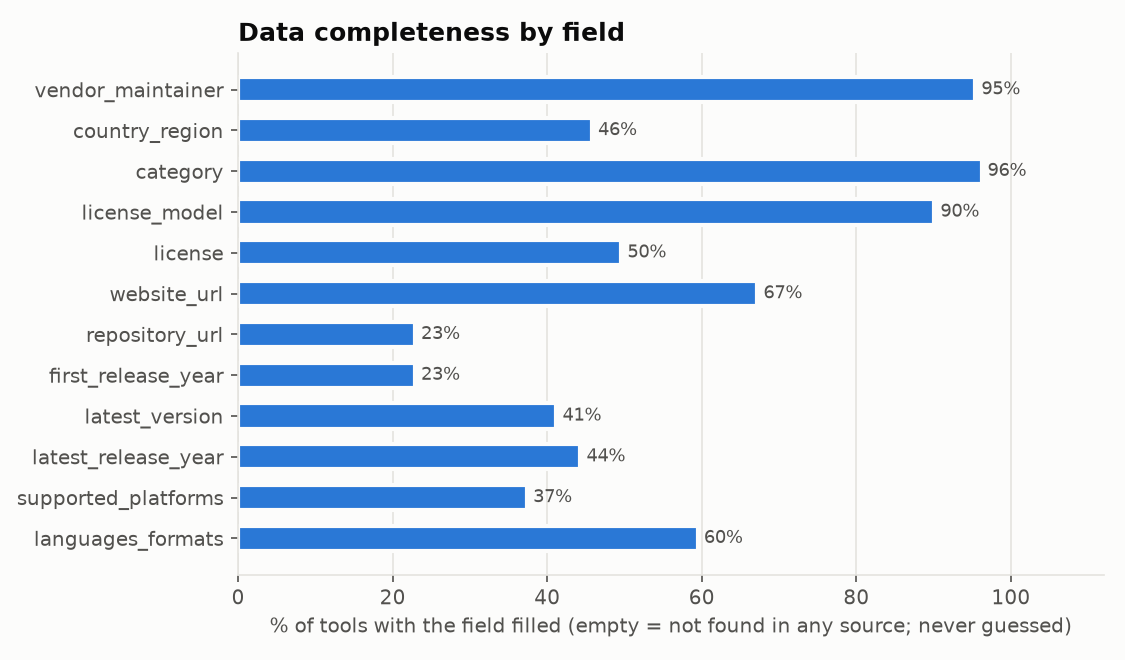

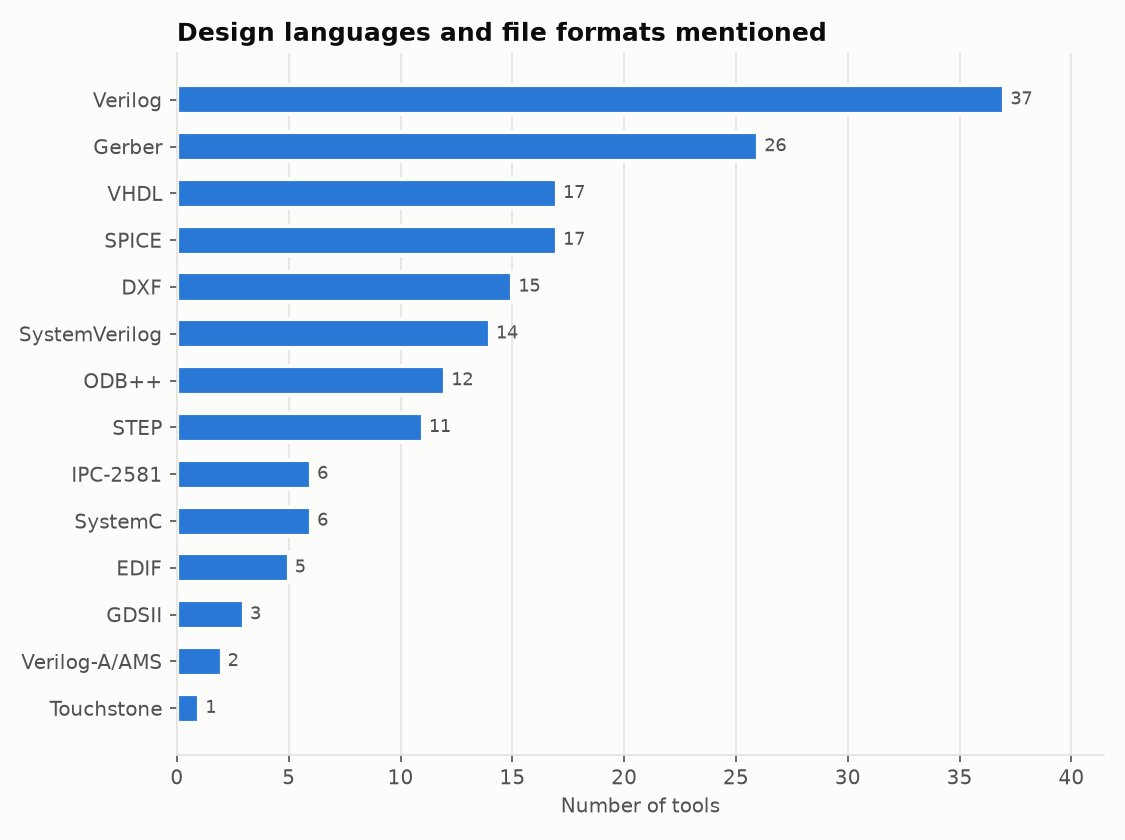

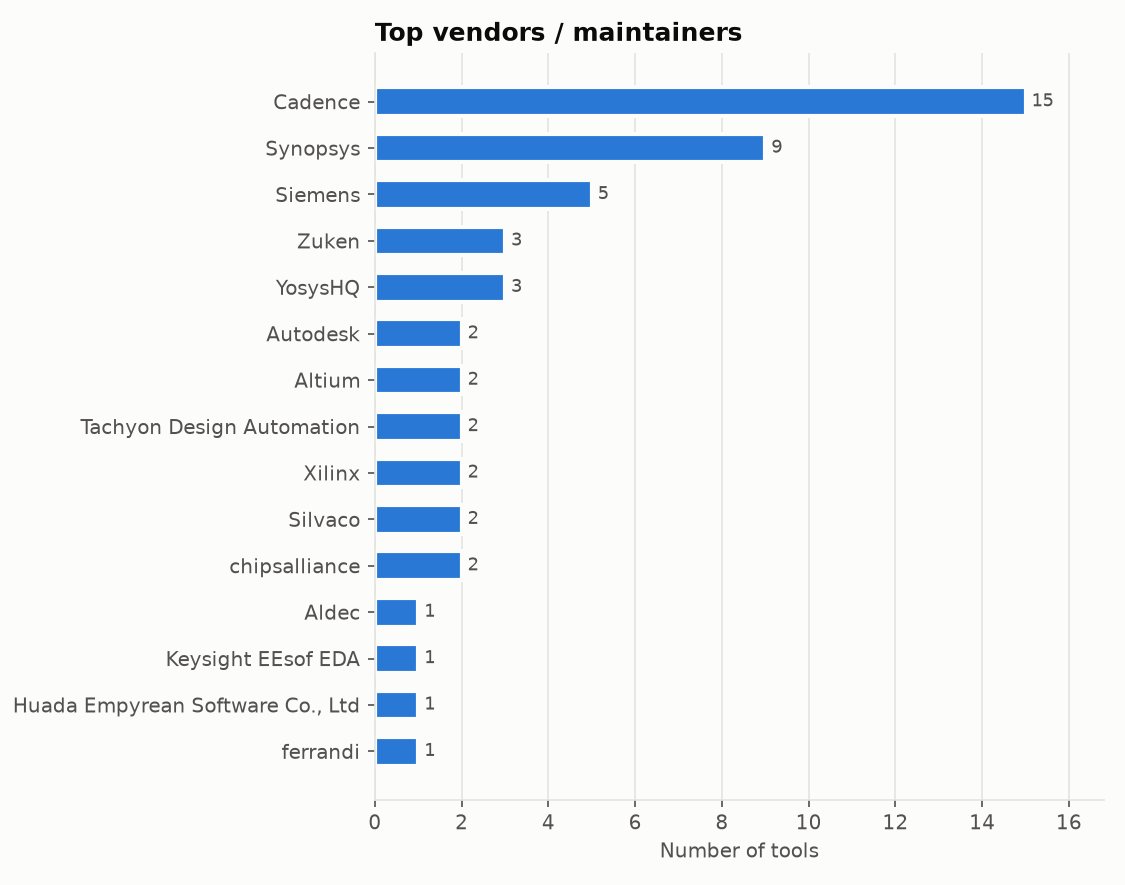

In [7]:
for name in ["platform_support.png", "data_completeness.png", "languages_formats.png", "top_vendors.png"]:
    display(Image(filename=str(ROOT / "outputs" / name)))

## 6. Traceability: any row back to its source URLs

Every row has a primary `source_url`; `provenance.csv` lists **every** page that contributed to it and
which fields that page reported.

In [8]:
rows = list(csv.DictReader(open(ROOT / "data/processed/eda_tools_clean.csv", encoding="utf-8")))
prov = list(csv.DictReader(open(ROOT / "data/processed/provenance.csv", encoding="utf-8")))
def trace(tool_id):
    r = next(r for r in rows if r["tool_id"] == tool_id)
    print({k: v for k, v in r.items() if v})
    for p in prov:
        if p["tool_id"] == tool_id:
            print("  <-", p["source_type"], p["source_url"], "| fields:", p["fields_reported"])
for tid in ["kicad", "verilator", "synopsys-primetime"]:
    if any(r["tool_id"] == tid for r in rows):
        trace(tid); print()

{'tool_id': 'kicad', 'tool_name': 'KiCad', 'vendor_maintainer': 'KiCad developers', 'category': 'pcb-design', 'additional_categories': 'analog-mixed-signal; layout-physical-verification; simulation', 'license_model': 'open-source', 'license': 'GPL-3.0', 'website_url': 'http://www.kicad.org', 'repository_url': 'https://gitlab.com/kicad', 'wikipedia_url': 'https://en.wikipedia.org/wiki/KiCad', 'first_release_year': '1992', 'latest_version': '10.0.6', 'latest_release_date': '2026-08-29', 'latest_release_year': '2026', 'supported_platforms': 'Linux; Windows; macOS', 'languages_formats': 'EDIF; Gerber; STEP', 'source_url': 'https://en.wikipedia.org/wiki/Comparison_of_EDA_software#Open_source_software_for_PCB_design', 'source_types': 'published_list; wikipedia_article', 'date_collected': '2026-10-15', 'source_verified': 'true', 'source_count': '2'}
  <- published_list https://en.wikipedia.org/wiki/Comparison_of_EDA_software#Open_source_software_for_PCB_design | fields: category; license_mode

## 7. A numpy cross-tab: category x licence model

In [9]:
cats = common.CATEGORIES
models = ["commercial", "open-source", "freeware", ""]
m = np.zeros((len(cats), len(models)), dtype=int)
for r in rows:
    if r["category"] in cats:
        m[cats.index(r["category"]), models.index(r["license_model"])] += 1
print("%-30s %10s %12s %9s %8s" % ("category", "commercial", "open-source", "freeware", "unknown"))
for c, line in zip(cats, m):
    print("%-30s %10d %12d %9d %8d" % (c, *line))
print("share open-source among tools with a known model: %.0f%%" % (100 * m[:, 1].sum() / max(m[:, :3].sum(), 1)))

category                       commercial  open-source  freeware  unknown
high-level-synthesis                    1            0         0        1
synthesis                               4            1         0        0
simulation                             24           15         0        0
verification                            4            2         0        4
place-and-route                         3            1         0        0
timing-signoff                          3            0         0        0
layout-physical-verification            2            3         0        3
analog-mixed-signal                     6            9         7        0
pcb-design                             19            7         0        1
fpga-toolchain                          1            4         0        1
share open-source among tools with a known model: 36%
